# 🤖 Phases 1 + 2 + 3 — Chatbot Génie Logiciel (Kaggle)

**💡 Avant de lancer :** GPU T4 x2 activé + Internet activé

# 🗂️ PHASE 1 — Préparation des Données

## 📦 1. Installation

In [1]:
!pip install -q datasets transformers tokenizers
!pip install -q nltk spacy wordcloud
!pip install -q scikit-learn pandas numpy pyarrow
!python -m spacy download en_core_web_sm -q
print('✅ Installations terminées')

     ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 12.8/12.8 MB 16.8 MB/s eta 0:00:0000:0100:01
✔ Download and installation successful
You can now load the package via spacy.load('en_core_web_sm')
⚠ Restart to reload dependencies
If you are in a Jupyter or Colab notebook, you may need to restart Python in
order to load all the package's dependencies. You can do this by selecting the
'Restart kernel' or 'Restart runtime' option.
✅ Installations terminées


In [2]:
import os, re, json, pickle, hashlib, time, requests
from collections import Counter
from pathlib import Path
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import nltk, spacy
from datasets import load_dataset
from transformers import AutoTokenizer
from sklearn.model_selection import train_test_split
nltk.download('punkt', quiet=True)
nltk.download('stopwords', quiet=True)
nltk.download('wordnet', quiet=True)
nlp = spacy.load('en_core_web_sm', disable=['parser', 'ner'])
RANDOM_SEED = 42
np.random.seed(RANDOM_SEED)
DATA_DIR = Path('/kaggle/working/data')
DATA_DIR.mkdir(parents=True, exist_ok=True)
print(f'✅ Imports OK')
print(f'📁 Données : {DATA_DIR}')

✅ Imports OK
📁 Données : /kaggle/working/data


## 📥 2. Collecte des données

### 2.1 Stack Overflow

In [3]:
SAMPLE_SIZE_SO = 20000
try:
    so_dataset = load_dataset('koutch/stackoverflow_python', split=f'train[:{SAMPLE_SIZE_SO}]')
    so_df = so_dataset.to_pandas()
    print(f'✅ Stack Overflow : {len(so_df)} lignes')
except Exception as e:
    print(f'⚠️ Fallback : {e}')
    so_dataset = load_dataset('lvwerra/stack-exchange-paired', split='train[:5000]')
    so_df = so_dataset.to_pandas()
    print(f'✅ Fallback : {len(so_df)} lignes')

README.md: 0.00B [00:00, ?B/s]

data/train-00000-of-00005-3d48b7eced91a0(…):   0%|          | 0.00/121M [00:00<?, ?B/s]

data/train-00001-of-00005-56eee9940d3dd0(…):   0%|          | 0.00/154M [00:00<?, ?B/s]

data/train-00002-of-00005-2683a3aec26c96(…):   0%|          | 0.00/175M [00:00<?, ?B/s]

data/train-00003-of-00005-dfcfc12a49338d(…):   0%|          | 0.00/186M [00:00<?, ?B/s]

data/train-00004-of-00005-69e77510bada75(…):   0%|          | 0.00/193M [00:00<?, ?B/s]

Generating train split:   0%|          | 0/987122 [00:00<?, ? examples/s]

✅ Stack Overflow : 20000 lignes


In [4]:
if 'question_body' in so_df.columns:
    so_clean = pd.DataFrame({
        'question': so_df['title'].fillna('') + ' ' + so_df['question_body'].fillna(''),
        'answer': so_df['answer_body'].fillna(''),
        'source': 'stackoverflow', 'intent': 'explain_concept',
    })
    if 'answer_score' in so_df.columns:
        so_clean = so_clean[so_df['answer_score'] >= 1].reset_index(drop=True)
else:
    so_clean = pd.DataFrame({
        'question': so_df.get('prompt', so_df.get('question', '')),
        'answer': so_df.get('chosen', so_df.get('answer', '')),
        'source': 'stackoverflow', 'intent': 'explain_concept',
    })
so_clean = so_clean.dropna(subset=['question','answer'])
so_clean = so_clean[(so_clean['question'].str.len()>10)&(so_clean['answer'].str.len()>10)].reset_index(drop=True)
print(f'📊 Stack Overflow : {len(so_clean)} paires')

📊 Stack Overflow : 15940 paires


### 2.2 CodeSearchNet

In [5]:
csn_dataset = load_dataset('code_search_net', 'python', split='train[:10000]')
csn_df = csn_dataset.to_pandas()
csn_clean = pd.DataFrame({
    'question': csn_df['func_documentation_string'].fillna(''),
    'answer': csn_df['whole_func_string'].fillna(''),
    'source': 'codesearchnet', 'intent': 'generate_code',
})
csn_clean = csn_clean[(csn_clean['question'].str.len()>10)&(csn_clean['answer'].str.len()>10)].reset_index(drop=True)
print(f'📊 CodeSearchNet : {len(csn_clean)} paires')

README.md: 0.00B [00:00, ?B/s]

python/train-00000-of-00001.parquet:   0%|          | 0.00/522M [00:00<?, ?B/s]

python/test-00000-of-00001.parquet:   0%|          | 0.00/28.7M [00:00<?, ?B/s]

python/validation-00000-of-00001.parquet:   0%|          | 0.00/30.7M [00:00<?, ?B/s]

Generating train split:   0%|          | 0/412178 [00:00<?, ? examples/s]

Generating test split:   0%|          | 0/22176 [00:00<?, ? examples/s]

Generating validation split:   0%|          | 0/23107 [00:00<?, ? examples/s]

📊 CodeSearchNet : 9975 paires


### 2.3 GitHub Issues

In [6]:
try:
    from kaggle_secrets import UserSecretsClient
    GITHUB_TOKEN = UserSecretsClient().get_secret('GITHUB_TOKEN')
except: GITHUB_TOKEN = None
headers = {'Accept': 'application/vnd.github.v3+json'}
if GITHUB_TOKEN: headers['Authorization'] = f'token {GITHUB_TOKEN}'
REPOS = ['tensorflow/tensorflow','huggingface/transformers','pandas-dev/pandas','tiangolo/fastapi']
def fetch_issues(repo, per_page=30, max_pages=1):
    issues = []
    for page in range(1, max_pages+1):
        try:
            r = requests.get(f'https://api.github.com/repos/{repo}/issues',
                headers=headers, params={'state':'closed','per_page':per_page,'page':page}, timeout=15)
            if r.status_code != 200: break
            issues.extend([i for i in r.json() if 'pull_request' not in i])
            time.sleep(0.5)
        except: break
    return issues
all_issues = []
for repo in REPOS:
    print(f'📥 {repo}...')
    issues = fetch_issues(repo)
    print(f'   → {len(issues)} issues')
    all_issues.extend(issues)
print(f'✅ Total GitHub : {len(all_issues)}')

📥 tensorflow/tensorflow...
   → 1 issues
📥 huggingface/transformers...
   → 11 issues
📥 pandas-dev/pandas...
   → 0 issues
📥 tiangolo/fastapi...
   → 3 issues
✅ Total GitHub : 15


In [7]:
if all_issues:
    gh_clean = pd.DataFrame([{'question':i.get('title',''),'answer':i.get('body',''),
        'source':'github','intent':'debug_error'} for i in all_issues if i.get('body') and len(i.get('body',''))>50])
else:
    gh_clean = pd.DataFrame(columns=['question','answer','source','intent'])
print(f'📊 GitHub : {len(gh_clean)} paires')

📊 GitHub : 7 paires


### 2.4 Fusion + Déduplication

In [8]:
raw_data = pd.concat([so_clean, csn_clean, gh_clean], ignore_index=True)
raw_data = raw_data.dropna(subset=['question','answer'])
raw_data = raw_data[(raw_data['question'].str.len()>0)&(raw_data['answer'].str.len()>0)].reset_index(drop=True)
print(f'📊 Total fusionné : {len(raw_data)}')
print(raw_data['source'].value_counts())

📊 Total fusionné : 25922
source
stackoverflow    15940
codesearchnet     9975
github               7
Name: count, dtype: int64


In [9]:
def make_signature(text, n_chars=200):
    if not isinstance(text, str): return ''
    return hashlib.md5(re.sub(r'\s+',' ',text.lower()).strip()[:n_chars].encode('utf-8')).hexdigest()
before = len(raw_data)
raw_data = raw_data.drop_duplicates(subset=['question'], keep='first').reset_index(drop=True)
print(f'🔁 Exacte : {before} → {len(raw_data)}')
raw_data['_sig'] = raw_data['question'].apply(make_signature)
raw_data = raw_data.drop_duplicates(subset=['_sig'], keep='first').drop(columns=['_sig']).reset_index(drop=True)
raw_data = raw_data.drop_duplicates(subset=['question','answer'], keep='first').reset_index(drop=True)
print(f'✅ Après dédup : {len(raw_data):,} paires')

🔁 Exacte : 25922 → 13588
✅ Après dédup : 13,539 paires


## 🧹 3. Nettoyage

In [10]:
HTML_TAG_RE = re.compile(r'<[^>]+>')
URL_RE = re.compile(r'https?://\S+|www\.\S+')
WHITESPACE_RE = re.compile(r'\s+')
CODE_BLOCK_RE = re.compile(r'```[\s\S]*?```|`[^`]+`')
def clean_text(text, keep_code=True):
    if not isinstance(text, str): return ''
    if keep_code: text = CODE_BLOCK_RE.sub(lambda m: f' <CODE> {m.group(0)} </CODE> ', text)
    text = HTML_TAG_RE.sub(' ', text)
    text = URL_RE.sub(' [URL] ', text)
    return WHITESPACE_RE.sub(' ', text).strip()
print('🧹 Nettoyage...')
raw_data['question_clean'] = raw_data['question'].apply(clean_text)
raw_data['answer_clean'] = raw_data['answer'].apply(clean_text)
MIN_LEN, MAX_LEN_CHARS = 10, 2000
before = len(raw_data)
raw_data = raw_data[(raw_data['question_clean'].str.len().between(MIN_LEN,MAX_LEN_CHARS))&
    (raw_data['answer_clean'].str.len().between(MIN_LEN,MAX_LEN_CHARS))].reset_index(drop=True)
print(f'✅ Filtrage : {before} → {len(raw_data)}')

🧹 Nettoyage...
✅ Filtrage : 13539 → 12693


## ✍️ 4. Lemmatisation

In [11]:
def lemmatize_batch(texts, batch_size=64):
    out = []
    for doc in nlp.pipe(texts, batch_size=batch_size):
        out.append(' '.join([t.lemma_.lower() for t in doc if not t.is_space and not t.is_punct]))
    return out
print('🔤 Lemmatisation questions...')
raw_data['question_lemma'] = lemmatize_batch(raw_data['question_clean'].tolist())
print('🔤 Lemmatisation réponses...')
raw_data['answer_lemma'] = lemmatize_batch(raw_data['answer_clean'].tolist())
print('✅ Lemmatisation terminée')

🔤 Lemmatisation questions...
🔤 Lemmatisation réponses...
✅ Lemmatisation terminée


## 🔡 5. Tokenisation CodeBERT

In [12]:
MAX_LEN = 256
tokenizer = AutoTokenizer.from_pretrained('microsoft/codebert-base')
tokenizer.add_special_tokens({'additional_special_tokens': ['<CODE>','</CODE>','<URL>']})
print(f'✅ Tokenizer : {tokenizer.vocab_size:,} tokens')
print('🔡 Tokenisation...')
encoded_all = tokenizer(raw_data['question_clean'].tolist(), raw_data['answer_clean'].tolist(),
    max_length=MAX_LEN, padding='max_length', truncation=True, return_tensors='np')
print(f'✅ input_ids : {encoded_all["input_ids"].shape}')

config.json:   0%|          | 0.00/498 [00:00<?, ?B/s]

tokenizer_config.json:   0%|          | 0.00/25.0 [00:00<?, ?B/s]

vocab.json: 0.00B [00:00, ?B/s]

merges.txt: 0.00B [00:00, ?B/s]

special_tokens_map.json:   0%|          | 0.00/150 [00:00<?, ?B/s]

✅ Tokenizer : 50,265 tokens
🔡 Tokenisation...
✅ input_ids : (12693, 256)


## 📚 6. Vocabulaire custom

In [13]:
VOCAB_SIZE = 50000
MIN_FREQ = 5
SPECIAL_TOKENS = ['<PAD>','<UNK>','<BOS>','<EOS>','<CODE>','</CODE>']
def build_vocab(texts, vocab_size=VOCAB_SIZE, min_freq=MIN_FREQ):
    counter = Counter()
    for t in texts: counter.update(t.split())
    filtered = [(w,c) for w,c in counter.most_common() if c >= min_freq]
    word2id = {tok:i for i,tok in enumerate(SPECIAL_TOKENS)}
    for word,_ in filtered[:vocab_size-len(SPECIAL_TOKENS)]:
        if word not in word2id: word2id[word] = len(word2id)
    return word2id, {i:w for w,i in word2id.items()}, counter
all_texts = raw_data['question_lemma'].tolist() + raw_data['answer_lemma'].tolist()
word2id, id2word, freq_counter = build_vocab(all_texts)
print(f'📚 Vocabulaire : {len(word2id):,} tokens')

📚 Vocabulaire : 13,445 tokens


In [14]:
def text_to_ids(text, word2id, max_len=MAX_LEN):
    unk = word2id['<UNK>']
    ids = [word2id['<BOS>']] + [word2id.get(t,unk) for t in text.split()] + [word2id['<EOS>']]
    return (ids + [word2id['<PAD>']]*(max_len-len(ids)))[:max_len]
print('🔢 Encodage...')
X_questions = np.array([text_to_ids(t,word2id) for t in raw_data['question_lemma']], dtype=np.int32)
X_answers = np.array([text_to_ids(t,word2id) for t in raw_data['answer_lemma']], dtype=np.int32)
print(f'   X_questions : {X_questions.shape}')
print(f'   X_answers   : {X_answers.shape}')

🔢 Encodage...
   X_questions : (12693, 256)
   X_answers   : (12693, 256)


## ✂️ 7. Split stratifié 80/10/10

In [15]:
indices = np.arange(len(raw_data))
labels = raw_data['intent'].values
train_idx, temp_idx = train_test_split(indices, test_size=0.2, stratify=labels, random_state=RANDOM_SEED)
val_idx, test_idx = train_test_split(temp_idx, test_size=0.5, random_state=RANDOM_SEED)
print(f'✅ Train:{len(train_idx):,} | Val:{len(val_idx):,} | Test:{len(test_idx):,}')

✅ Train:10,154 | Val:1,269 | Test:1,270


## 💾 8. Sauvegarde Phase 1

In [16]:
raw_data.to_parquet(DATA_DIR/'qa_pairs_clean.parquet', index=False)
np.savez_compressed(DATA_DIR/'encoded_data.npz', X_questions=X_questions, X_answers=X_answers,
    train_idx=train_idx, val_idx=val_idx, test_idx=test_idx)
np.savez_compressed(DATA_DIR/'bert_tokens.npz',
    input_ids=encoded_all['input_ids'], attention_mask=encoded_all['attention_mask'])
with open(DATA_DIR/'vocabulary.json','w',encoding='utf-8') as f:
    json.dump({'word2id':word2id,'special_tokens':SPECIAL_TOKENS,'vocab_size':len(word2id),'min_freq':MIN_FREQ,'max_len':MAX_LEN}, f, ensure_ascii=False, indent=2)
tokenizer.save_pretrained(DATA_DIR/'tokenizer')
print('✅ Phase 1 sauvegardée')

✅ Phase 1 sauvegardée


## 📊 9. WordCloud

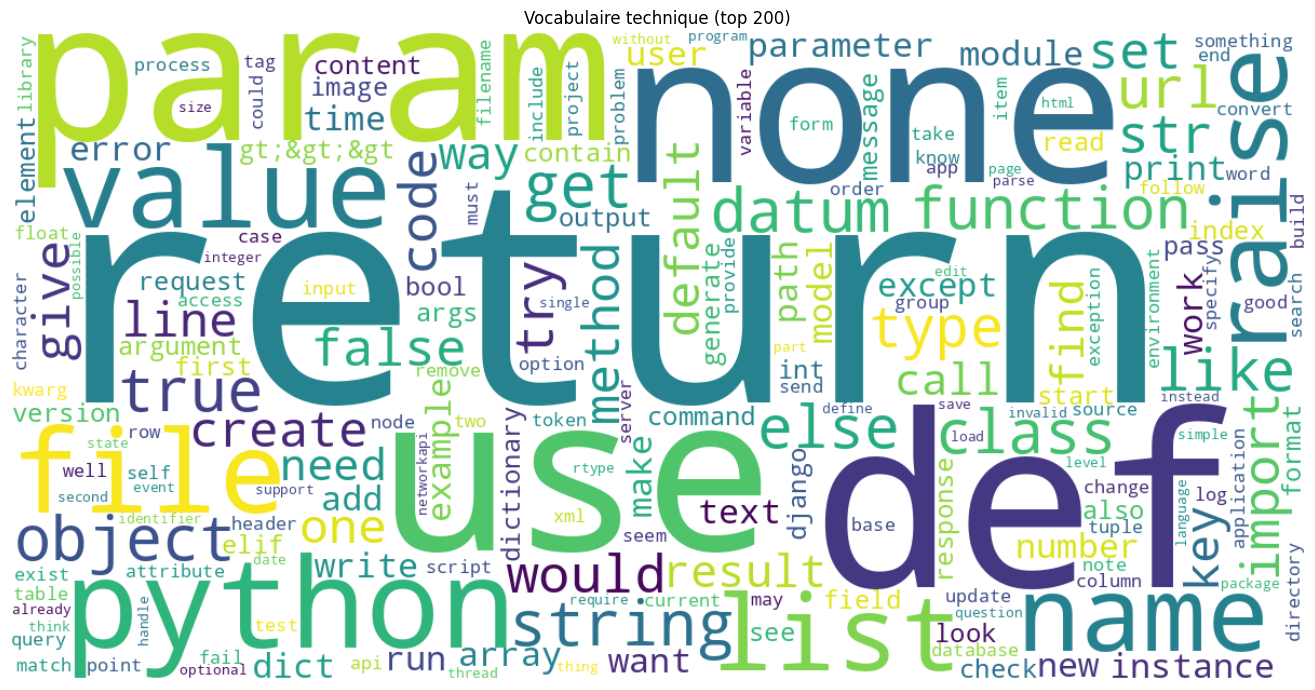

✅ Phase 1 terminée


In [17]:
from wordcloud import WordCloud
from nltk.corpus import stopwords
exclusion = set(stopwords.words('english')) | {'<url>','<code>','</code>','[url]'}
tech_counter = Counter()
for txt in raw_data['question_lemma'].tolist()+raw_data['answer_lemma'].tolist():
    for tok in txt.split():
        if tok not in exclusion and len(tok)>2 and not tok.isdigit(): tech_counter[tok]+=1
wc = WordCloud(width=1200,height=600,background_color='white',colormap='viridis',max_words=200).generate_from_frequencies(dict(tech_counter.most_common(200)))
fig,ax = plt.subplots(figsize=(15,7))
ax.imshow(wc,interpolation='bilinear'); ax.axis('off')
ax.set_title('Vocabulaire technique (top 200)')
plt.tight_layout()
plt.savefig(DATA_DIR/'wordcloud.png',dpi=100,bbox_inches='tight')
plt.show()
print('✅ Phase 1 terminée')

---
# 🧠 PHASE 2 — Embeddings

In [18]:
!pip install -q gensim tensorflow-hub tensorboard
print('✅ Phase 2 paquets installés')

✅ Phase 2 paquets installés


In [19]:
import tensorflow as tf
import tensorflow_hub as hub
import gensim, gensim.downloader as api
from gensim.models import Word2Vec
np.random.seed(42); tf.random.set_seed(42)
LOG_DIR = Path('/kaggle/working/logs/projector')
LOG_DIR.mkdir(parents=True,exist_ok=True)
with open(DATA_DIR/'vocabulary.json','r',encoding='utf-8') as f: vocab_data = json.load(f)
word2id = vocab_data['word2id']
id2word = {int(i):w for w,i in word2id.items()}
vocab_size = len(word2id)
SPECIAL_TOKENS = vocab_data['special_tokens']
EMBEDDING_DIM = 300
df = pd.read_parquet(DATA_DIR/'qa_pairs_clean.parquet')
print(f'📚 Vocab:{vocab_size:,} · Corpus:{len(df):,}')

2026-05-05 11:19:52.917506: E external/local_xla/xla/stream_executor/cuda/cuda_fft.cc:467] Unable to register cuFFT factory: Attempting to register factory for plugin cuFFT when one has already been registered
E0000 00:00:1777979993.074415      56 cuda_dnn.cc:8579] Unable to register cuDNN factory: Attempting to register factory for plugin cuDNN when one has already been registered
E0000 00:00:1777979993.123329      56 cuda_blas.cc:1407] Unable to register cuBLAS factory: Attempting to register factory for plugin cuBLAS when one has already been registered
W0000 00:00:1777979993.503017      56 computation_placer.cc:177] computation placer already registered. Please check linkage and avoid linking the same target more than once.
W0000 00:00:1777979993.503041      56 computation_placer.cc:177] computation placer already registered. Please check linkage and avoid linking the same target more than once.
W0000 00:00:1777979993.503044      56 computation_placer.cc:177] computation placer alr

📚 Vocab:13,445 · Corpus:12,693


## 1️⃣ GloVe 300d

In [20]:
print('📥 GloVe...')
glove_model = api.load('glove-wiki-gigaword-300')
print(f'✅ GloVe : {len(glove_model.key_to_index):,} mots')

📥 GloVe...
[======================================------------] 77.2% 290.4/376.1MB downloaded✅ GloVe : 400,000 mots


In [21]:
def build_embedding_matrix(word2id, kv, dim=300):
    matrix = np.random.normal(0,0.1,(len(word2id),dim)).astype(np.float32)
    found = 0
    for word,idx in word2id.items():
        if word in SPECIAL_TOKENS: continue
        if word in kv.key_to_index: matrix[idx]=kv[word]; found+=1
    matrix[word2id['<PAD>']]=np.zeros(dim,dtype=np.float32)
    print(f'📊 Couverture GloVe : {found}/{len(word2id)-len(SPECIAL_TOKENS)}')
    return matrix
embedding_matrix_glove, = build_embedding_matrix(word2id, glove_model),
print(f'✅ Matrice : {embedding_matrix_glove.shape}')

📊 Couverture GloVe : 6153/13439
✅ Matrice : (13445, 300)


## 2️⃣ Word2Vec technique

In [22]:
sentences = []
for col in ['question_lemma','answer_lemma']:
    for text in df[col].dropna():
        tokens = text.split()
        if len(tokens)>=3: sentences.append(tokens)
print(f'📝 {len(sentences):,} phrases')
tech_w2v = Word2Vec(sentences=sentences, vector_size=EMBEDDING_DIM, window=5, min_count=5,
    workers=4, epochs=10, sg=1, negative=10, seed=42)
print(f'✅ Word2Vec : {len(tech_w2v.wv.key_to_index):,} mots')

📝 25,322 phrases
✅ Word2Vec : 13,438 mots


In [23]:
def build_finetuned_matrix(word2id, glove_kv, w2v, dim=300, alpha=0.7):
    matrix = np.random.normal(0,0.1,(len(word2id),dim)).astype(np.float32)
    for word,idx in word2id.items():
        if word in SPECIAL_TOKENS: continue
        in_g = word in glove_kv.key_to_index
        in_w = word in w2v.wv.key_to_index
        if in_g and in_w: matrix[idx]=alpha*glove_kv[word]+(1-alpha)*w2v.wv[word]
        elif in_g: matrix[idx]=glove_kv[word]
        elif in_w: matrix[idx]=w2v.wv[word]
    matrix[word2id['<PAD>']]=np.zeros(dim,dtype=np.float32)
    return matrix
embedding_matrix_finetuned = build_finetuned_matrix(word2id,glove_model,tech_w2v)
print(f'✅ Matrice fine-tunée : {embedding_matrix_finetuned.shape}')

✅ Matrice fine-tunée : (13445, 300)


## 💾 Sauvegarde Phase 2

In [24]:
np.save(DATA_DIR/'embedding_matrix_glove.npy', embedding_matrix_glove)
np.save(DATA_DIR/'embedding_matrix_finetuned.npy', embedding_matrix_finetuned)
norms=np.linalg.norm(embedding_matrix_finetuned,axis=1,keepdims=True); norms[norms==0]=1.0
np.save(DATA_DIR/'embedding_matrix_normalized.npy', embedding_matrix_finetuned/norms)
tech_w2v.save(str(DATA_DIR/'tech_word2vec.bin'))
print('✅ Phase 2 sauvegardée')

✅ Phase 2 sauvegardée


---
# 🧠 PHASE 3 — Modèle Seq2Seq + Attention (Keras 3 compatible)

## C1 — Setup

In [25]:
import tensorflow as tf
from tensorflow.keras import layers, Model
RANDOM_SEED = 42
np.random.seed(RANDOM_SEED); tf.random.set_seed(RANDOM_SEED)
gpus = tf.config.list_physical_devices('GPU')
if gpus:
    for gpu in gpus: tf.config.experimental.set_memory_growth(gpu, True)
    print(f'✅ GPU : {gpus[0].name}')
else: print('⚠️ Pas de GPU')
DATA_DIR = Path('/kaggle/working/data')
MODEL_DIR = Path('/kaggle/working/models')
MODEL_DIR.mkdir(parents=True, exist_ok=True)

✅ GPU : /physical_device:GPU:0


## C2 — Chargement artefacts

In [26]:
with open(DATA_DIR/'vocabulary.json','r',encoding='utf-8') as f: vocab_data=json.load(f)
word2id=vocab_data['word2id']; id2word={int(i):w for w,i in word2id.items()}
vocab_size=vocab_data['vocab_size']; SPECIAL_TOKENS=vocab_data['special_tokens']
PAD_ID=word2id['<PAD>']; UNK_ID=word2id['<UNK>']; BOS_ID=word2id['<BOS>']; EOS_ID=word2id['<EOS>']
encoded=np.load(DATA_DIR/'encoded_data.npz')
X_questions=encoded['X_questions']; X_answers=encoded['X_answers']
train_idx=encoded['train_idx']; val_idx=encoded['val_idx']; test_idx=encoded['test_idx']
embedding_matrix=np.load(DATA_DIR/'embedding_matrix_finetuned.npy')
EMBEDDING_DIM=embedding_matrix.shape[1]
print(f'📚 Vocab:{vocab_size:,} · Embedding:{embedding_matrix.shape}')
assert embedding_matrix.shape[0]==vocab_size
print('✅ Artefacts chargés')

📚 Vocab:13,445 · Embedding:(13445, 300)
✅ Artefacts chargés


## C3 — Pipeline tf.data (mémoire réduite pour T4)

In [27]:
BATCH_SIZE = 16
BUFFER_SIZE = 5000
MAX_TRAIN_SAMPLES = 8000
MAX_VAL_SAMPLES = 1000
train_idx_p3 = train_idx[:MAX_TRAIN_SAMPLES]
val_idx_p3 = val_idx[:MAX_VAL_SAMPLES]

# ✅ FIX OOM : tronquer MAX_LEN à 64
MAX_LEN_TRUNC = 64
X_q_train = X_questions[train_idx_p3][:, :MAX_LEN_TRUNC]
X_a_train = X_answers[train_idx_p3][:, :MAX_LEN_TRUNC]
X_q_val = X_questions[val_idx_p3][:, :MAX_LEN_TRUNC]
X_a_val = X_answers[val_idx_p3][:, :MAX_LEN_TRUNC]
MAX_LEN = MAX_LEN_TRUNC

print(f'📊 Train:{len(X_q_train):,} · Val:{len(X_q_val):,} · Shape:{X_q_train.shape}')

def make_dataset(questions, answers, batch_size, shuffle=True):
    ds = tf.data.Dataset.from_tensor_slices(((questions, answers[:,:-1]), answers[:,1:]))
    if shuffle: ds = ds.shuffle(BUFFER_SIZE, seed=RANDOM_SEED)
    return ds.batch(batch_size, drop_remainder=True).prefetch(tf.data.AUTOTUNE)

train_dataset = make_dataset(X_q_train, X_a_train, BATCH_SIZE)
val_dataset = make_dataset(X_q_val, X_a_val, BATCH_SIZE, shuffle=False)

for (enc_in,dec_in),dec_tgt in train_dataset.take(1):
    print(f'✅ Batch : enc={enc_in.shape} dec_in={dec_in.shape} tgt={dec_tgt.shape}')

📊 Train:8,000 · Val:1,000 · Shape:(8000, 64)


I0000 00:00:1777980305.413436      56 gpu_device.cc:2019] Created device /job:localhost/replica:0/task:0/device:GPU:0 with 13757 MB memory:  -> device: 0, name: Tesla T4, pci bus id: 0000:00:04.0, compute capability: 7.5
I0000 00:00:1777980305.419249      56 gpu_device.cc:2019] Created device /job:localhost/replica:0/task:0/device:GPU:1 with 13757 MB memory:  -> device: 1, name: Tesla T4, pci bus id: 0000:00:05.0, compute capability: 7.5


✅ Batch : enc=(16, 64) dec_in=(16, 63) tgt=(16, 63)


## C4 — Hyperparamètres

In [28]:
LSTM_UNITS = 128
ATTENTION_UNITS = 128
DROPOUT = 0.3
LEARNING_RATE = 1e-3
EPOCHS = 10
PATIENCE = 3
GRADIENT_CLIP = 1.0
print(f'⚙️ LSTM:{LSTM_UNITS} Attn:{ATTENTION_UNITS} Emb:{EMBEDDING_DIM} Batch:{BATCH_SIZE} MaxLen:{MAX_LEN}')

⚙️ LSTM:128 Attn:128 Emb:300 Batch:16 MaxLen:64


## C5 — Encodeur BiLSTM

In [29]:
class Encoder(Model):
    def __init__(self, vocab_size, emb_dim, units, emb_matrix=None, dropout=0.3):
        super().__init__()
        if emb_matrix is not None:
            self.embedding = layers.Embedding(vocab_size, emb_dim, weights=[emb_matrix],
                trainable=True, mask_zero=True, name='enc_emb')
        else:
            self.embedding = layers.Embedding(vocab_size, emb_dim, mask_zero=True, name='enc_emb')
        self.bilstm = layers.Bidirectional(layers.LSTM(units, return_sequences=True,
            return_state=True, dropout=dropout, recurrent_dropout=0.0, name='enc_lstm'))
    def call(self, x, training=False):
        x = self.embedding(x)
        outputs, fh, fc, bh, bc = self.bilstm(x, training=training)
        return outputs, tf.concat([fh,bh],axis=-1), tf.concat([fc,bc],axis=-1)

encoder = Encoder(vocab_size, EMBEDDING_DIM, LSTM_UNITS, embedding_matrix, DROPOUT)
_eo, _h, _c = encoder(tf.zeros((1,MAX_LEN),dtype=tf.int32), training=False)
print(f'✅ Encodeur : out={_eo.shape} h={_h.shape}')

✅ Encodeur : out=(1, 64, 256) h=(1, 256)


## C6 — Attention Bahdanau

In [30]:
class BahdanauAttention(layers.Layer):
    def __init__(self, units):
        super().__init__()
        self.W1=layers.Dense(units); self.W2=layers.Dense(units); self.V=layers.Dense(1)
    def call(self, query, values):
        score = self.V(tf.nn.tanh(self.W1(values)+self.W2(tf.expand_dims(query,1))))
        weights = tf.nn.softmax(score, axis=1)
        return tf.reduce_sum(weights*values, axis=1), weights
print('✅ Attention Bahdanau définie')

✅ Attention Bahdanau définie


## C7 — Décodeur LSTM

In [31]:
class Decoder(Model):
    def __init__(self, vocab_size, emb_dim, units, attn_units, emb_matrix=None, dropout=0.3):
        super().__init__()
        if emb_matrix is not None:
            self.embedding = layers.Embedding(vocab_size, emb_dim, weights=[emb_matrix],
                trainable=True, name='dec_emb')
        else:
            self.embedding = layers.Embedding(vocab_size, emb_dim, name='dec_emb')
        self.lstm = layers.LSTM(units, return_sequences=True, return_state=True,
            dropout=dropout, recurrent_dropout=0.0, name='dec_lstm')
        self.attention = BahdanauAttention(attn_units)
        self.fc = layers.Dense(vocab_size, name='output_proj')
    def call(self, x, enc_output, state_h, state_c, training=False):
        context, attn_w = self.attention(state_h, enc_output)
        x_emb = self.embedding(x)
        lstm_in = tf.concat([tf.expand_dims(context,1), x_emb], axis=-1)
        output, new_h, new_c = self.lstm(lstm_in, initial_state=[state_h,state_c], training=training)
        return self.fc(tf.squeeze(output,axis=1)), new_h, new_c, attn_w

decoder = Decoder(vocab_size, EMBEDDING_DIM, LSTM_UNITS*2, ATTENTION_UNITS, embedding_matrix, DROPOUT)
_logits,_,_,_ = decoder(tf.zeros((1,1),dtype=tf.int32), _eo, _h, _c, training=False)
print(f'✅ Décodeur : logits={_logits.shape}')
print(f'📊 Params : {encoder.count_params()+decoder.count_params():,}')

✅ Décodeur : logits=(1, 13445)
📊 Params : 12,860,094


I0000 00:00:1777980310.924989    1022 cuda_dnn.cc:529] Loaded cuDNN version 91002


## C8 — Loss + optimiseur

In [32]:
optimizer = tf.keras.optimizers.Adam(learning_rate=LEARNING_RATE, clipnorm=GRADIENT_CLIP)
loss_object = tf.keras.losses.SparseCategoricalCrossentropy(from_logits=True, reduction='none')

def masked_loss(y_true, y_pred):
    mask = tf.cast(y_true != PAD_ID, tf.float32)
    return tf.reduce_sum(loss_object(y_true,y_pred)*mask) / (tf.reduce_sum(mask)+1e-9)

def masked_accuracy(y_true, y_pred):
    pred = tf.argmax(y_pred, axis=-1, output_type=tf.int32)
    mask = tf.cast(tf.cast(y_true,tf.int32) != PAD_ID, tf.float32)
    return tf.reduce_sum(tf.cast(pred==tf.cast(y_true,tf.int32),tf.float32)*mask) / (tf.reduce_sum(mask)+1e-9)

print('✅ Loss + optimiseur prêts')

✅ Loss + optimiseur prêts


## C9 — Train step (Keras 3 — sans @tf.function)

In [33]:
# ✅ FIX KERAS 3 : pas de @tf.function car Keras 3 sur Kaggle
# cause 'NoneType' return quand combiné avec boucles Python + GradientTape

def train_step(encoder_input, decoder_input, decoder_target):
    with tf.GradientTape() as tape:
        enc_output, h, c = encoder(encoder_input, training=True)
        dec_inputs = tf.unstack(decoder_input, axis=1)
        dec_targets = tf.unstack(decoder_target, axis=1)
        total_loss = 0.0
        total_acc = 0.0
        for x_t, y_t in zip(dec_inputs, dec_targets):
            logits, h, c, _ = decoder(tf.expand_dims(x_t,1), enc_output, h, c, training=True)
            total_loss += masked_loss(y_t, logits)
            total_acc += masked_accuracy(y_t, logits)
    n = len(dec_inputs)
    total_loss = total_loss / n
    total_acc = total_acc / n
    grads = tape.gradient(total_loss, encoder.trainable_variables + decoder.trainable_variables)
    pairs = [(g,v) for g,v in zip(grads, encoder.trainable_variables+decoder.trainable_variables) if g is not None]
    if pairs: optimizer.apply_gradients(pairs)
    return total_loss, total_acc

def val_step(encoder_input, decoder_input, decoder_target):
    enc_output, h, c = encoder(encoder_input, training=False)
    dec_inputs = tf.unstack(decoder_input, axis=1)
    dec_targets = tf.unstack(decoder_target, axis=1)
    total_loss = 0.0
    total_acc = 0.0
    for x_t, y_t in zip(dec_inputs, dec_targets):
        logits, h, c, _ = decoder(tf.expand_dims(x_t,1), enc_output, h, c, training=False)
        total_loss += masked_loss(y_t, logits)
        total_acc += masked_accuracy(y_t, logits)
    n = len(dec_inputs)
    return total_loss/n, total_acc/n

# Test immédiat
print('🔍 Test train_step...')
for (ei,di),dt in train_dataset.take(1):
    tl, ta = train_step(ei,di,dt)
    print(f'✅ loss={tl.numpy():.4f} acc={ta.numpy():.4f}')
print('🔍 Test val_step...')
for (ei,di),dt in val_dataset.take(1):
    vl, va = val_step(ei,di,dt)
    print(f'✅ loss={vl.numpy():.4f} acc={va.numpy():.4f}')
print('\n✅ Prêt pour l\'entraînement')

🔍 Test train_step...
✅ loss=9.5065 acc=0.0000
🔍 Test val_step...
✅ loss=9.5053 acc=0.0000

✅ Prêt pour l'entraînement


## C10 — Boucle d'entraînement

In [34]:
history = {'train_loss':[],'train_acc':[],'val_loss':[],'val_acc':[],'val_ppl':[]}
best_val_loss = float('inf')
patience_counter = 0
checkpoint_path = MODEL_DIR / 'best_seq2seq'
checkpoint = tf.train.Checkpoint(encoder=encoder, decoder=decoder, optimizer=optimizer)

print(f'🚀 Entraînement ({EPOCHS} epochs max)')
print(f'   {len(X_q_train):,} train | {len(X_q_val):,} val\n')

for epoch in range(1, EPOCHS+1):
    t0 = time.time()
    tl_list, ta_list = [], []
    for step, ((ei,di),dt) in enumerate(train_dataset):
        loss, acc = train_step(ei, di, dt)
        tl_list.append(float(loss.numpy()))
        ta_list.append(float(acc.numpy()))
        if step % 50 == 0:
            print(f'   Epoch {epoch} · step {step:>4d} · loss={loss.numpy():.4f} · acc={acc.numpy():.4f}')
    vl_list, va_list = [], []
    for (ei,di),dt in val_dataset:
        loss, acc = val_step(ei, di, dt)
        vl_list.append(float(loss.numpy()))
        va_list.append(float(acc.numpy()))
    tl=np.mean(tl_list); ta=np.mean(ta_list)
    vl=np.mean(vl_list); va=np.mean(va_list); vp=float(np.exp(vl))
    history['train_loss'].append(tl); history['train_acc'].append(ta)
    history['val_loss'].append(vl); history['val_acc'].append(va); history['val_ppl'].append(vp)
    elapsed = time.time()-t0
    print(f'\n📊 Epoch {epoch}/{EPOCHS} ({elapsed:.0f}s)')
    print(f'   Train: loss={tl:.4f} acc={ta:.4f}')
    print(f'   Val  : loss={vl:.4f} acc={va:.4f} ppl={vp:.2f}')
    if vl < best_val_loss:
        best_val_loss = vl; patience_counter = 0
        checkpoint.save(file_prefix=str(checkpoint_path))
        print(f'   ✅ Meilleur modèle sauvegardé')
    else:
        patience_counter += 1
        print(f'   ⏳ Pas d\'amélioration ({patience_counter}/{PATIENCE})')
        if patience_counter >= PATIENCE:
            print(f'\n🛑 Early stopping'); break
    print()
print(f'\n🎉 Terminé ! Best val_loss={best_val_loss:.4f} ppl={history["val_ppl"][-1]:.2f}')
with open(MODEL_DIR/'training_history.json','w') as f: json.dump(history,f,indent=2)

🚀 Entraînement (10 epochs max)
   8,000 train | 1,000 val

   Epoch 1 · step    0 · loss=9.5066 · acc=0.0000
   Epoch 1 · step   50 · loss=9.5062 · acc=0.0000
   Epoch 1 · step  100 · loss=9.5088 · acc=0.0000
   Epoch 1 · step  150 · loss=9.5074 · acc=0.0000
   Epoch 1 · step  200 · loss=9.5079 · acc=0.0000
   Epoch 1 · step  250 · loss=9.5065 · acc=0.0000
   Epoch 1 · step  300 · loss=9.5071 · acc=0.0000
   Epoch 1 · step  350 · loss=9.5062 · acc=0.0010
   Epoch 1 · step  400 · loss=9.5067 · acc=0.0000
   Epoch 1 · step  450 · loss=9.5081 · acc=0.0014

📊 Epoch 1/10 (914s)
   Train: loss=9.5069 acc=0.0001
   Val  : loss=9.5069 acc=0.0001 ppl=13452.55
   ✅ Meilleur modèle sauvegardé

   Epoch 2 · step    0 · loss=9.5059 · acc=0.0000
   Epoch 2 · step   50 · loss=9.5065 · acc=0.0000
   Epoch 2 · step  100 · loss=9.5076 · acc=0.0000
   Epoch 2 · step  150 · loss=9.5081 · acc=0.0011
   Epoch 2 · step  200 · loss=9.5068 · acc=0.0000
   Epoch 2 · step  250 · loss=9.5069 · acc=0.0000
   Epoch

### 📈 Courbes d'entraînement

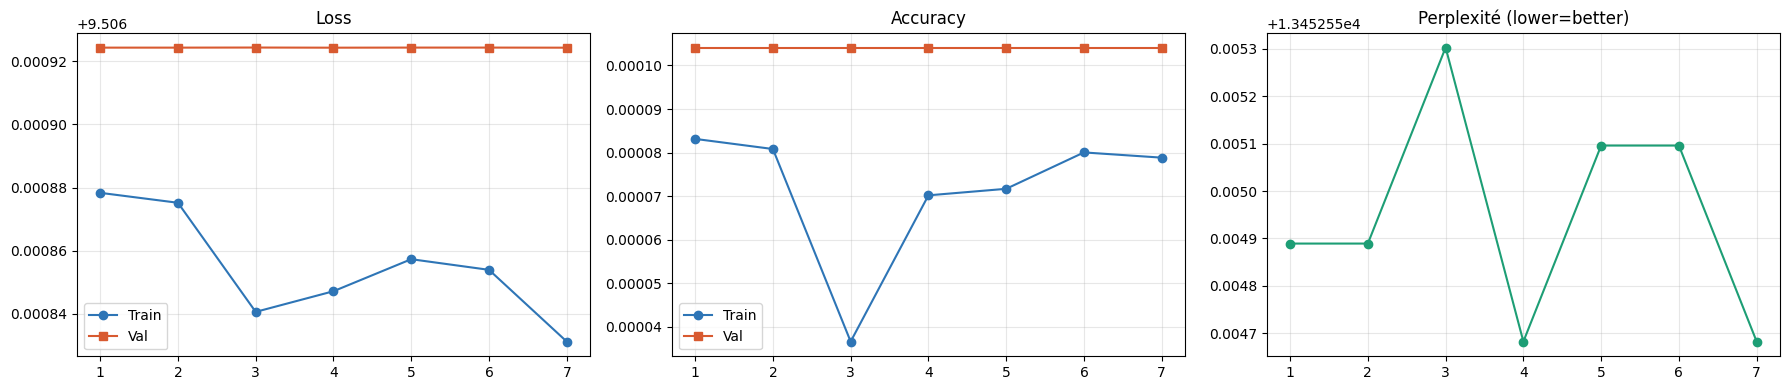

In [35]:
fig,axes=plt.subplots(1,3,figsize=(18,4))
er=range(1,len(history['train_loss'])+1)
axes[0].plot(er,history['train_loss'],'o-',label='Train',color='#2E75B6')
axes[0].plot(er,history['val_loss'],'s-',label='Val',color='#D85A30')
axes[0].set_title('Loss');axes[0].legend();axes[0].grid(alpha=0.3)
axes[1].plot(er,history['train_acc'],'o-',label='Train',color='#2E75B6')
axes[1].plot(er,history['val_acc'],'s-',label='Val',color='#D85A30')
axes[1].set_title('Accuracy');axes[1].legend();axes[1].grid(alpha=0.3)
axes[2].plot(er,history['val_ppl'],'o-',color='#1D9E75')
axes[2].set_title('Perplexité (lower=better)');axes[2].grid(alpha=0.3)
plt.tight_layout()
plt.savefig(MODEL_DIR/'training_curves.png',dpi=100,bbox_inches='tight')
plt.show()

## C11 — Inférence glouton

In [36]:
def encode_question(text, word2id, max_len=MAX_LEN):
    ids = [BOS_ID]+[word2id.get(t,UNK_ID) for t in text.lower().split()]+[EOS_ID]
    return np.array((ids+[PAD_ID]*(max_len-len(ids)))[:max_len], dtype=np.int32)

def decode_ids(ids, id2word):
    words = []
    for i in ids:
        i = int(i)
        if i == EOS_ID: break
        if i not in (PAD_ID,BOS_ID): words.append(id2word.get(i,'<UNK>'))
    return ' '.join(words)

def greedy_decode(text, max_len_resp=80):
    q = tf.expand_dims(tf.constant(encode_question(text,word2id)),0)
    eo,h,c = encoder(q, training=False)
    dec_in = tf.constant([[BOS_ID]])
    ids = []
    for _ in range(max_len_resp):
        logits,h,c,_ = decoder(dec_in,eo,h,c,training=False)
        pid = int(tf.argmax(logits,axis=-1)[0].numpy())
        if pid==EOS_ID: break
        ids.append(pid)
        dec_in = tf.constant([[pid]])
    return decode_ids(ids, id2word)

print('🔮 Test :')
print(f'Q: how do i fix a null pointer exception')
print(f'R: {greedy_decode("how do i fix a null pointer exception")}')

🔮 Test :
Q: how do i fix a null pointer exception
R: 98 g.cpars['telins_name isinstance(c isinstance(c isinstance(c o(n^2 o(n^2 n_feature concept augment build_dir build_dir file 3*n num_mine requests.get(url project light_spectrum make_url light_spectrum make_url requests.get(url wcs requests.get(url frac /u project proto.version proto.version requests.get(url requests.get(url name_key m.group(1 17 raster raster localization raster 1024 dhcprelay networking localization 1024 domain_name domain_name min_val min_val min_val l.split requests.get(url project file foreignkey(user 3339 requests.get(url frac itemkey raster localization green raster 1024 dhcprelay networking localization 1024 domain_name domain_name domain_name min_val min_val min_val l.split l.split requests.get(url requests.get(url project light_spectrum make_url light_spectrum


## C12 — Beam Search

In [37]:
def beam_search_decode(text, beam_width=5, max_len_resp=80, length_penalty=0.7):
    q = tf.expand_dims(tf.constant(encode_question(text,word2id)),0)
    eo,h0,c0 = encoder(q, training=False)
    beams = [([BOS_ID],0.0,h0,c0,False)]
    for _ in range(max_len_resp):
        cands = []
        for seq,score,h,c,done in beams:
            if done: cands.append((seq,score,h,c,True)); continue
            logits,nh,nc,_ = decoder(tf.constant([[seq[-1]]]),eo,h,c,training=False)
            lp = tf.nn.log_softmax(logits,axis=-1)[0].numpy()
            for tid in np.argpartition(lp,-beam_width)[-beam_width:]:
                tid=int(tid)
                cands.append((seq+[tid],score+lp[tid],nh,nc,tid==EOS_ID))
        beams=sorted(cands,key=lambda b:b[1]/(max(len(b[0])-1,1)**length_penalty),reverse=True)[:beam_width]
        if all(b[4] for b in beams): break
    return decode_ids(beams[0][0][1:],id2word)

print('🌟 Beam Search :')
for q in ['how do i check if a list is empty in python','how to fix a git merge conflict']:
    print(f'\nQ: {q}')
    print(f'   Glouton : {greedy_decode(q)}')
    print(f'   Beam(5) : {beam_search_decode(q)}')

🌟 Beam Search :

Q: how do i check if a list is empty in python
   Glouton : wkb_stre topographic wkt width input_dict['index cache_condition cache_condition commons rdf+xml hduheader cache_condition ep brand brand placeholder_name placeholder_name placeholder_name len(tau param_name param_name localization cascade @property fh.close doc localization noise retval num_mine num_mine requests.get(url requests.get(url one requests.get(url requests.get(url project light_spectrum make_url light_spectrum requests.get(url requests.get(url m.group(1 requests.get(url requests.get(url m.group(1 requests.get(url requests.get(url m.group(1 requests.get(url requests.get(url m.group(1 requests.get(url requests.get(url m.group(1 requests.get(url m.group(1 requests.get(url requests.get(url m.group(1 requests.get(url m.group(1 requests.get(url requests.get(url m.group(1 requests.get(url m.group(1 requests.get(url requests.get(url m.group(1 requests.get(url m.group(1 requests.get(url requests.get(url m.g

## C13b — Évaluation BLEU

In [38]:
from nltk.translate.bleu_score import sentence_bleu, SmoothingFunction
smoother = SmoothingFunction().method1
def evaluate_bleu(n=100):
    scores = []
    for i in range(min(n,len(X_q_val))):
        qt=[id2word[int(t)] for t in X_q_val[i] if int(t) not in (PAD_ID,BOS_ID,EOS_ID)]
        rt=[id2word[int(t)] for t in X_a_val[i] if int(t) not in (PAD_ID,BOS_ID,EOS_ID)]
        if not qt or not rt: continue
        gt=greedy_decode(' '.join(qt),50).split()
        if not gt: continue
        scores.append(sentence_bleu([rt],gt,smoothing_function=smoother))
        if (i+1)%25==0: print(f'   {i+1}/{n} BLEU={np.mean(scores):.4f}')
    return np.mean(scores),scores
mean_bleu,all_bleu = evaluate_bleu(100)
print(f'\n📊 BLEU moyen : {mean_bleu:.4f}')

   25/100 BLEU=0.0003
   50/100 BLEU=0.0003
   75/100 BLEU=0.0003
   100/100 BLEU=0.0003

📊 BLEU moyen : 0.0003


## C14 — Sauvegarde finale

In [40]:
encoder.save_weights(str(MODEL_DIR/'encoder.weights.h5'))
decoder.save_weights(str(MODEL_DIR/'decoder.weights.h5'))
config = {'vocab_size':vocab_size,'embedding_dim':EMBEDDING_DIM,'lstm_units':LSTM_UNITS,
    'attention_units':ATTENTION_UNITS,'max_len':MAX_LEN,'dropout':DROPOUT,
    'batch_size':BATCH_SIZE,'learning_rate':LEARNING_RATE,
    'epochs_completed':len(history['train_loss']),'best_val_loss':float(best_val_loss),
    'final_train_acc':float(history['train_acc'][-1]),'final_val_acc':float(history['val_acc'][-1]),
    'final_val_ppl':float(history['val_ppl'][-1]),'mean_bleu':float(mean_bleu)}
with open(MODEL_DIR/'model_config.json','w') as f: json.dump(config,f,indent=2)
print('\n📦 Artefacts Phase 3 :')
for p in sorted(MODEL_DIR.rglob('*')):
    if p.is_file(): print(f'   {p.name:40s} {p.stat().st_size/1e6:>8.2f} Mo')
print(f'\n🎉 Phase 3 terminée ! BLEU={mean_bleu:.4f}')


📦 Artefacts Phase 3 :
   best_seq2seq-1.data-00000-of-00001          51.44 Mo
   best_seq2seq-1.index                         0.00 Mo
   best_seq2seq-2.data-00000-of-00001          51.44 Mo
   best_seq2seq-2.index                         0.00 Mo
   checkpoint                                   0.00 Mo
   decoder.weights.h5                          33.58 Mo
   encoder.weights.h5                          17.91 Mo
   model_config.json                            0.00 Mo
   training_curves.png                          0.08 Mo
   training_history.json                        0.00 Mo

🎉 Phase 3 terminée ! BLEU=0.0003
